<a href="https://colab.research.google.com/github/kuunalmistry/Google_Colab_Clg_Experiments_Projects/blob/main/Assignment_No_15_LSTM_KuunalMistry_2410130.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

In [31]:
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch Version: {torch.__version__}")

PyTorch Version: 2.11.0+cpu


In [32]:
dataset = pd.read_csv('/content/airline-passengers - airline-passengers.csv')
display(dataset.head())

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


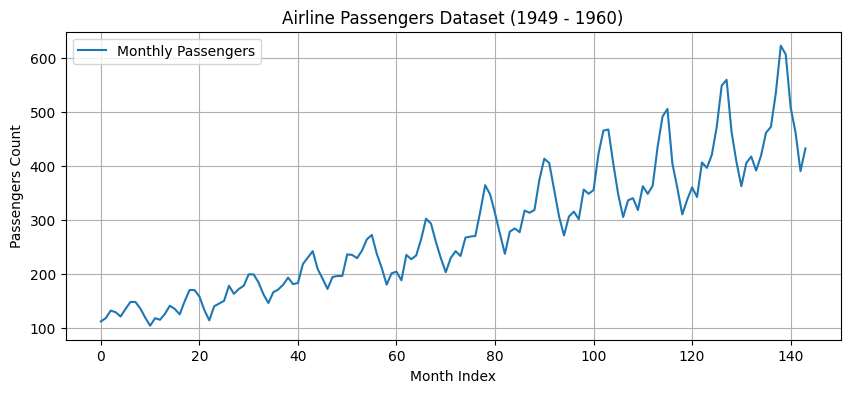

In [33]:
plt.figure(figsize=(10, 4))
plt.plot(dataset['Passengers'],  label='Monthly Passengers')
plt.title('Airline Passengers Dataset (1949 - 1960)')
plt.xlabel('Month Index')
plt.ylabel('Passengers Count')
plt.grid(True)
plt.legend()
plt.show()

In [34]:
data = dataset['Passengers'].values.astype(float).reshape(-1, 1)

In [35]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

In [36]:
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return torch.tensor(np.array(xs), dtype=torch.float32), torch.tensor(np.array(ys), dtype=torch.float32)

SEQ_LENGTH = 12  # Lookback window (12 months of historical data)
X, y = create_sequences(scaled_data, SEQ_LENGTH)

In [37]:
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

X_train shape: torch.Size([105, 12, 1]) | y_train shape: torch.Size([105, 1])
X_test shape:  torch.Size([27, 12, 1])  | y_test shape:  torch.Size([27, 1])


In [38]:
class AirPassengerLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1):
        super(AirPassengerLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # LSTM Layer
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)

        # Fully Connected Layer to output prediction
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Initialize hidden state and cell state with zeros
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size)

        out, _ = self.lstm(x, (h0, c0))

        # Take output from the last time step
        out = self.fc(out[:, -1, :])
        return out

model = AirPassengerLSTM(input_size=1, hidden_size=64, num_layers=1, output_size=1)
print(model)

AirPassengerLSTM(
  (lstm): LSTM(1, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [39]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

EPOCHS = 200

train_losses = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()

    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    if epoch % 20 == 0:
        print(f"Epoch [{epoch}/{EPOCHS}] - Loss: {loss.item():.5f}")

Epoch [20/200] - Loss: 0.01690
Epoch [40/200] - Loss: 0.00628
Epoch [60/200] - Loss: 0.00509
Epoch [80/200] - Loss: 0.00453
Epoch [100/200] - Loss: 0.00333
Epoch [120/200] - Loss: 0.00365
Epoch [140/200] - Loss: 0.00207
Epoch [160/200] - Loss: 0.00149
Epoch [180/200] - Loss: 0.00205
Epoch [200/200] - Loss: 0.00133


In [40]:
model.eval()
with torch.no_grad():
    train_predict = model(X_train)
    test_predict = model(X_test)

In [41]:
train_predict = scaler.inverse_transform(train_predict.numpy())
y_train_actual = scaler.inverse_transform(y_train.numpy())

In [42]:
plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

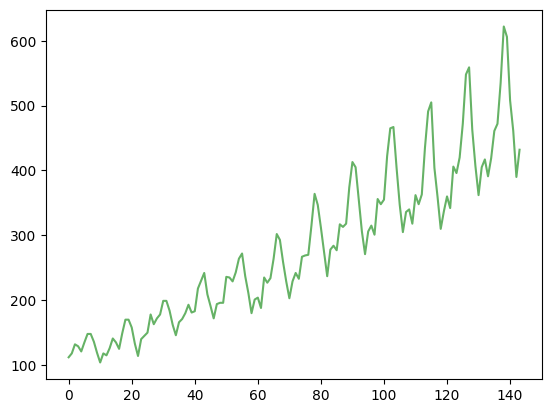

In [49]:
plt.plot(scaler.inverse_transform(scaled_data), label='Actual Data', color='green', alpha=0.6)

In [44]:
train_plot = np.empty_like(scaled_data)
train_plot[:, :] = np.nan
train_plot[SEQ_LENGTH:len(train_predict) + SEQ_LENGTH] = train_predict

/tmp/ipykernel_1300/2146009260.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  test_plot[len(train_predict) + SEQ_LENGTH:] = test_predict


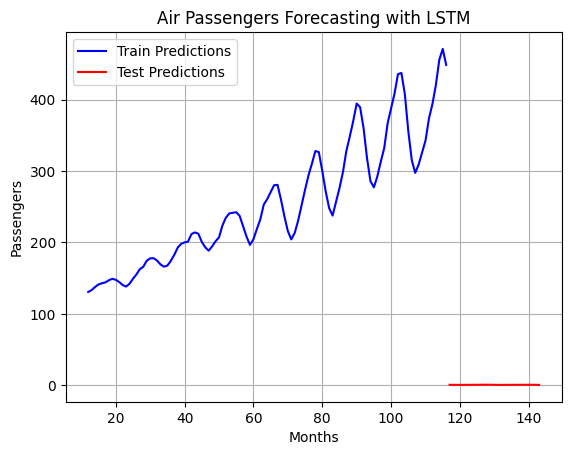

In [50]:
test_plot = np.empty_like(scaled_data)
test_plot[:, :] = np.nan
test_plot[len(train_predict) + SEQ_LENGTH:] = test_predict

plt.plot(train_plot, label='Train Predictions', color='blue')
plt.plot(test_plot, label='Test Predictions', color='red')

plt.title('Air Passengers Forecasting with LSTM')
plt.xlabel('Months')
plt.ylabel('Passengers')
plt.legend()
plt.grid(True)
plt.show()